# 1.08. Метрики и доверие к тесту

**План занятия**

1. Сквозной кейс и роли метрик: что смотреть сначала, а что потом.
2. Закон Гудхарта: что бывает, если оптимизировать одну метрику.
3. Как проверить метрику: чувствительность и согласие с целью.
4. Прокси и суррогаты: одной корреляции мало.
5. Горизонт теста и долгосрочные эффекты.
6. Ловушки интерпретации: метрика-SRM, ratio-метрики, потеря телеметрии.
7. Триггеринг и разбавление эффекта.
8. Парадокс Симпсона: меняющиеся доли и сегменты, зависящие от воздействия.
9. Сегменты и множественность, неполные воронки, закон Твайман.
10. Чек-лист доверия к тесту.

Занятие устроено как набор ловушек. Каждая показана на симуляции с известной истиной: сначала мы видим убедительный результат, потом выясняем, почему ему нельзя верить, и учимся замечать это заранее. Базовые проверки (SRM, A/A, мощность, подглядывание, выбросы, новизна) разобраны в других занятиях, здесь мы на них только ссылаемся.

### Библиотеки

Все библиотеки стандартные.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'


def diff_p(a, b):
    """Разность средних b - a, её стандартная ошибка и p-value (критерий Уэлча)."""
    delta = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return delta, se, 2 * st.norm.sf(abs(delta / se))


def rel_effect(a, b):
    """Относительный эффект b/a - 1 и его стандартная ошибка (дельта-метод, независимые группы)."""
    ma, mb = a.mean(), b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    return mb / ma - 1, np.sqrt(vb / ma ** 2 + va * mb ** 2 / ma ** 4)


def ratio_effect(num_a, den_a, num_b, den_b):
    """Относительный эффект ratio-метрики sum(num)/sum(den) и его стандартная ошибка (линеаризация)."""
    ra, rb = num_a.sum() / den_a.sum(), num_b.sum() / den_b.sum()

    def var(num, den, r):
        return ((num - r * den) / den.mean()).var(ddof=1) / len(num)

    se = np.sqrt(var(num_b, den_b, rb) / ra ** 2 + var(num_a, den_a, ra) * rb ** 2 / ra ** 4)
    return rb / ra - 1, se


def pct(x, digits=1):
    return f'{100 * x:+.{digits}f}%'

## Сквозной кейс и роли метрик

Все примеры занятия живут в одном продукте: приложении доставки еды. Главная цель бизнеса — чтобы пользователи заказывали больше и дольше оставались. Мы формулируем её как **долгосрочную метрику (north star)**: число заказов на пользователя за 28 дней. Проблема в том, что узнать её можно только через четыре недели, а тест нужно закончить раньше. Поэтому в тесте мы смотрим не на одну метрику, а на несколько, и у каждой своя роль.

Роли удобно разделять по тому, **что мы с метрикой делаем**. Эта классификация из статьи Microsoft ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)) дополняет разбиение success/guardrail/deterioration/quality из [занятия 1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB): она отвечает на вопрос «в каком порядке читать результат», а не «как считать поправки».

* **Метрики качества данных.** Первый вопрос: можно ли вообще доверять эксперименту. Главная из них — доля пользователей в группах, то есть [SRM](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%A2%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%BD%D0%BE%D0%B2%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D0%B0%D0%BD%D0%B8%D1%86%D1%8B%20%D1%87%D0%B5%D0%BA%D0%B0%D1%83%D1%82%D0%B0.%20AB%20%D1%82%D0%B5%D1%81%D1%82%20%D0%BD%D0%B0%20z%20%D1%82%D0%B5%D1%81%D1%82%D0%B5). Сюда же относятся доли потерянной телеметрии и сверка клиентских событий с серверными.
* **OEC (Overall Evaluation Criterion).** Метрика, по которой решаем, запускать ли изменение. Она измеряется за время теста, но должна указывать на долгосрочную ценность. Идеально, когда она одна. В нашем кейсе это заказы за первые 7 дней.
* **Guardrail-метрики.** Метрики, которые не должны заметно ухудшиться, даже если OEC растёт: отписки от пушей, время доставки, доля возвратов.
* **Локальные и диагностические метрики.** Клики по конкретной кнопке, шаги воронки, CTR отдельного блока. Они объясняют, откуда взялось движение OEC, но сами решения не принимают.

Порядок чтения результата следует из ролей: сначала убеждаемся, что данным можно верить, потом смотрим OEC, потом проверяем, что ничего не сломали, и только потом разбираемся, почему так вышло.

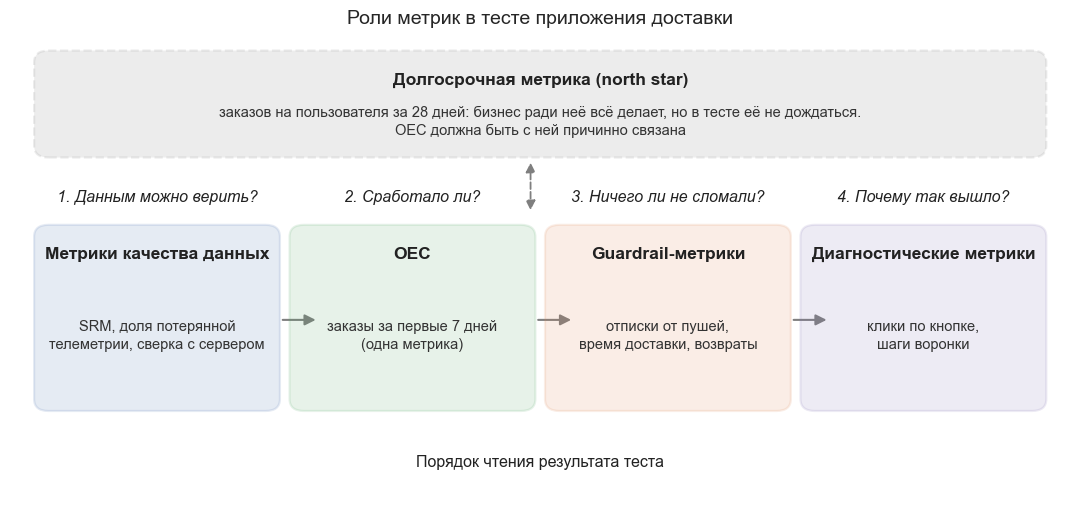

In [2]:
def draw_roles():
    fig, ax = plt.subplots(figsize=(11, 5.4))
    ax.set_xlim(0, 11)
    ax.set_ylim(0, 6)
    ax.axis('off')
    ax.grid(False)

    def box(x, y, w, h, title, body, color, dashed=False):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.05,rounding_size=0.15', facecolor=color, edgecolor=GRAY if dashed else color,
                                    alpha=.14, linewidth=1.6, linestyle='--' if dashed else '-'))
        ax.text(x + w / 2, y + h - .32, title, ha='center', va='center', fontsize=12.5, fontweight='bold', color='#222222')
        ax.text(x + w / 2, y + h / 2 - .22, body, ha='center', va='center', fontsize=10.5, color='#333333', linespacing=1.35)

    box(.3, 4.5, 10.4, 1.25, 'Долгосрочная метрика (north star)', 'заказов на пользователя за 28 дней: бизнес ради неё всё делает, но в тесте её не дождаться.\nOEC должна быть с ней причинно связана', GRAY, dashed=True)
    steps = [
        (.3, 'Данным можно верить?', 'Метрики качества данных', 'SRM, доля потерянной\nтелеметрии, сверка с сервером', BLUE),
        (2.95, 'Сработало ли?', 'OEC', 'заказы за первые 7 дней\n(одна метрика)', GREEN),
        (5.6, 'Ничего ли не сломали?', 'Guardrail-метрики', 'отписки от пушей,\nвремя доставки, возвраты', ORANGE),
        (8.25, 'Почему так вышло?', 'Диагностические метрики', 'клики по кнопке,\nшаги воронки', PURPLE),
    ]
    for k, (x, question, title, body, color) in enumerate(steps):
        ax.text(x + 1.225, 3.95, f'{k + 1}. {question}', ha='center', va='center', fontsize=11.5, color='#222222', style='italic')
        box(x, 1.3, 2.45, 2.25, title, body, color)
        if k < 3:
            ax.add_patch(FancyArrowPatch((x + 2.5, 2.4), (x + 2.9, 2.4), arrowstyle='-|>', mutation_scale=16, color=GRAY, linewidth=1.5))
    ax.add_patch(FancyArrowPatch((5.4, 3.75), (5.4, 4.42), arrowstyle='<|-|>', mutation_scale=14, color=GRAY, linewidth=1.3, linestyle='--'))
    ax.text(5.5, .55, 'Порядок чтения результата теста', ha='center', fontsize=11.5, color='#222222')
    ax.set_title('Роли метрик в тесте приложения доставки', fontsize=14, pad=8)
    plt.tight_layout()
    plt.show()


draw_roles()

## Закон Гудхарта: что бывает, если оптимизировать одну метрику

Метрика полезна, пока она остаётся индикатором. Как только её превращают в цель, её начинают двигать любыми способами, в том числе вредными. Это закон Гудхарта: когда мера становится целью, она перестаёт быть хорошей мерой.

Допустим, команда пушей получила цель «вырастить число сессий на пользователя». Она тестирует 200 изменений. Среди них есть честные: они немного повышают и сессии, и заказы. И есть **накрутка**: более навязчивые пуши, которые дают много сессий, но раздражают людей, и заказов становится меньше. Мы закладываем в модель, что накрутка составляет 30% идей (это допущение, не факт про реальные команды).

Сравним две политики запуска:

* **A.** Запускаем всё, где сессии значимо выросли.
* **B.** Запускаем то же, но дополнительно требуем, чтобы заказы не просели сильнее, чем на 2%: нижняя граница 95% доверительного интервала по заказам должна быть выше −2%. Это guardrail.

Истинные эффекты нам известны, поэтому мы можем честно подсчитать, что получил бы продукт.

In [3]:
def goodhart_round(rng, n=200, gaming=.3, se_sessions=.6, se_orders=.6, margin=-2.0):
    """Одна «жизнь» команды: n идей, истинные эффекты в % на сессии и заказы, измеренные с шумом."""
    is_gaming = rng.random(n) < gaming
    sessions = np.where(is_gaming, rng.normal(2.0, 1.0, n), rng.normal(.5, 1.0, n))
    orders = np.where(is_gaming, rng.normal(-1.2, .6, n), .6 * sessions + rng.normal(0, .5, n))
    s_hat = sessions + rng.normal(0, se_sessions, n)
    o_hat = orders + rng.normal(0, se_orders, n)
    ship_a = s_hat / se_sessions > 1.96
    ship_b = ship_a & (o_hat - 1.96 * se_orders > margin)
    return {'policy': ['A: только сессии', 'B: сессии + guardrail'],
            'shipped': [ship_a.sum(), ship_b.sum()],
            'gaming_shipped': [(ship_a & is_gaming).sum(), (ship_b & is_gaming).sum()],
            'sessions': [sessions[ship_a].sum(), sessions[ship_b].sum()],
            'orders': [orders[ship_a].sum(), orders[ship_b].sum()]}


rounds = [goodhart_round(np.random.default_rng(seed)) for seed in range(500)]
gh = pd.DataFrame([{'policy': r['policy'][k], **{key: r[key][k] for key in ('shipped', 'gaming_shipped', 'sessions', 'orders')}} for r in rounds for k in (0, 1)])
summary = gh.groupby('policy').agg(shipped=('shipped', 'mean'), gaming_shipped=('gaming_shipped', 'mean'),
                                   sessions=('sessions', 'mean'), orders_mean=('orders', 'mean'), orders_p10=('orders', lambda x: x.quantile(.1)),
                                   orders_p90=('orders', lambda x: x.quantile(.9)))
summary.columns = ['запущено идей', 'из них накрутка', 'Σ эффект на сессии, %', 'Σ эффект на заказы, % (среднее)', 'то же, 10-й перцентиль', 'то же, 90-й перцентиль']
print(summary.round(1).to_string())

                       запущено идей  из них накрутка  Σ эффект на сессии, %  Σ эффект на заказы, % (среднее)  то же, 10-й перцентиль  то же, 90-й перцентиль
policy                                                                                                                                                       
A: только сессии                84.9             45.4                  167.2                            -18.6                   -33.2                    -5.1
B: сессии + guardrail           53.4             14.9                   94.4                             25.2                    16.0                    33.9


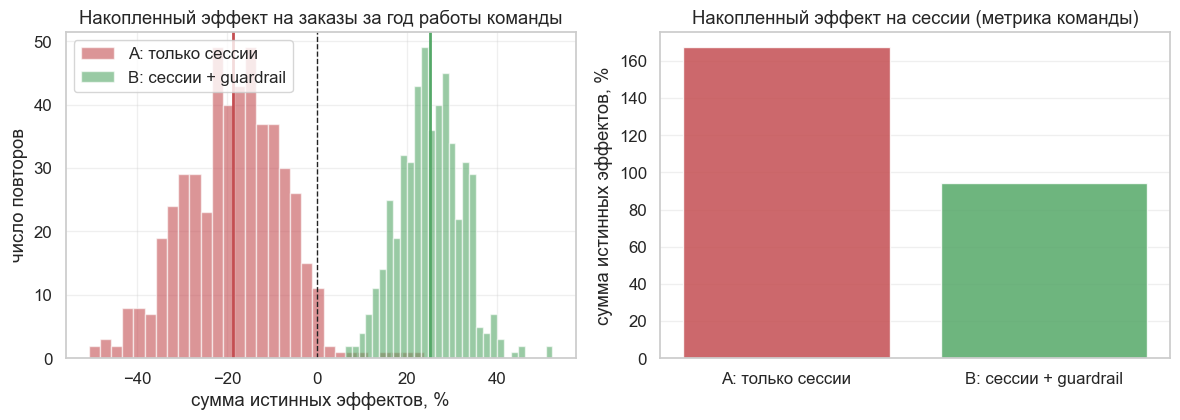

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
colors = {'A: только сессии': RED, 'B: сессии + guardrail': GREEN}
for name, color in colors.items():
    part = gh[gh.policy == name]
    axes[0].hist(part.orders, bins=30, color=color, alpha=.6, label=name)
    axes[0].axvline(part.orders.mean(), color=color, linewidth=2)
    axes[1].bar(name, part.sessions.mean(), color=color, alpha=.85)
axes[0].axvline(0, color='#222222', linewidth=1, linestyle='--')
axes[0].set_title('Накопленный эффект на заказы за год работы команды')
axes[0].set_xlabel('сумма истинных эффектов, %')
axes[0].set_ylabel('число повторов')
axes[0].legend(loc='upper left')
axes[1].set_title('Накопленный эффект на сессии (метрика команды)')
axes[1].set_ylabel('сумма истинных эффектов, %')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Политика A выигрывает по метрике, на которой её оценивают: сумма эффектов на сессии около +167 п.п. против +94 у политики B. Но платой за это становятся накрученные идеи: A запускает в среднем 45 из них (из 85 запущенных идей), и **заказы в сумме уходят в минус**: в среднем около −19 п.п., а даже 90-й перцентиль по повторам остаётся отрицательным (около −5). Политика B запускает 15 накруток и 38 честных идей и даёт около +25 п.п. по заказам (от +16 до +34 между 10-м и 90-м перцентилями). Guardrail отсекает почти всю накрутку, зато и сессий добавляется меньше: часть честных идей тоже не проходит проверку, потому что guardrail измеряется с шумом. Это обычная цена защиты, и платить её надо осознанно.

Правило отсюда простое: **у метрики-цели всегда должна быть пара из guardrail-метрик, определённых до запуска.** Определять их после, когда мы уже видим данные, значит искать подходящий результат. Ещё лучше иметь **контрметрику**, которая ломается ровно тогда, когда метрику накручивают: для сессий это доля сессий, закончившихся заказом, или доля отписавшихся.

Эта модель игрушечная: доля накрутки, размеры эффектов и шум выбраны нами, и конкретные цифры нельзя переносить на ваш продукт. Но механизм настоящий: отбор по одной метрике собирает вместе и честные идеи, и те, что просто сильнее двигают метрику.

### Проверьте себя

**Ситуация 1.** Команда оптимизирует «среднее время в приложении». Тест нового экрана показал +9% к времени в приложении, а число заказов на пользователя не изменилось (p = 0.4). Запускаем?

<details>
<summary>Ответ</summary>

Нельзя просто радоваться росту времени. Время может расти из-за того, что пользователю труднее найти нужное: он дольше листает и ищет. Нужны контрметрики: доля сессий с заказом, время до первого заказа, доля поисков без результата. Отсутствие эффекта на заказах при росте времени как раз намекает на ухудшение, а не на выигрыш. Рост времени сам по себе нельзя считать победой, пока не проверено, что он идёт вместе с ростом долгосрочной ценности.
</details>

## Как проверить метрику: чувствительность и согласие с целью

Выбрать OEC интуитивно можно, а можно проверить на данных. У хорошей метрики два свойства.

* **Чувствительность.** Сколько данных нужно метрике, чтобы показать значимое отличие заданной величины. Чем выше чувствительность, тем короче тесты. Она зависит от объёма данных, дисперсии метрики и от того, какие эксперименты мы вообще проводим: метрика, чувствительная для одного типа изменений, может быть слепа к другому ([Dmitriev, Wu, 2016](https://exp-platform.com/Documents/2016CIKM_MeasuringMetrics.pdf)).
* **Согласие с целью (направленность).** Если метрика значимо выросла, то это действительно хорошо для долгосрочной цели. Чувствительная, но несогласованная метрика хуже бесполезной: она уверенно ведёт не туда.

Измерять эти свойства можно на **корпусе прошлых экспериментов**, для которых итог известен: у каждого эксперимента есть метка «хорошо» или «плохо» для долгосрочной цели, поставленная не только по метрикам, но и по ручным оценкам, обратной связи и повторным проверкам. Тогда для каждой метрики считаем долю экспериментов, где она значимо двинулась в согласии с меткой, и долю, где против неё. Именно так строится метрика LabelAgreement в системе Bing, описанной у Dmitriev и Wu: она учитывает и чувствительность (метрика должна быть значимой), и согласие с метками.

Построим такой корпус для нашего кейса: 400 прошлых тестов с известным истинным эффектом θ на заказы за 28 дней. Для каждого теста у нас есть измеренный эффект на четыре кандидата в OEC: сессии за 7 дней, заказы за 7 дней, выручку за 28 дней и CTR пуша. Корпус синтетический: связи между метриками и θ мы задали сами, но способ оценки такой же, как на реальных данных.

In [5]:
def make_corpus(rng, n=400, gaming=.3):
    """Корпус прошлых тестов: истинный эффект θ на заказы за 28 дней и измеренные эффекты на кандидатов в OEC (в %)."""
    is_gaming = rng.random(n) < gaming
    theta = np.where(is_gaming, rng.normal(-1.5, 1.0, n), rng.normal(.5, 2.0, n))
    spec = {  # метрика: (связь с θ, шум связи, стандартная ошибка измерения)
        'сессии за 7 дней': (1.0, .8, 0.5),
        'заказы за 7 дней': (.8, .4, .7),
        'выручка за 28 дней': (1.0, .3, 2.0),
        'CTR пуша': (.1, 2.0, .4),
    }
    out = {'theta': theta}
    for name, (slope, noise, se) in spec.items():
        shift = np.where(is_gaming, 2.5, 0.0) if name.startswith('сессии') else (.8 if name == 'CTR пуша' else 0.0)
        out[name] = slope * theta + shift + rng.normal(0, noise, n) + rng.normal(0, se, n)
        out[name + '|se'] = np.full(n, se)
    return pd.DataFrame(out)


def corpus_metrics(corpus, label_threshold=1.0):
    """Для каждой метрики: доли тестов, где она значимо двинулась по метке, против метки или не двинулась."""
    labelled = corpus[np.abs(corpus.theta) >= label_threshold]
    rows = []
    for name in [c for c in corpus.columns if c not in ('theta',) and not c.endswith('|se')]:
        significant = np.abs(labelled[name] / labelled[name + '|se']) > 1.96
        same = np.sign(labelled[name]) == np.sign(labelled.theta)
        rows.append({'метрика': name, 'чувствительность': significant.mean(), 'согласие с меткой': (significant & same).mean(),
                     'против метки': (significant & ~same).mean(), 'не двинулась': 1 - significant.mean(), 'тестов с меткой': len(labelled)})
    return pd.DataFrame(rows).set_index('метрика')


corpus = make_corpus(np.random.default_rng(7))
table = corpus_metrics(corpus)
print(table.round(2).to_string())

                    чувствительность  согласие с меткой  против метки  не двинулась  тестов с меткой
метрика                                                                                             
сессии за 7 дней                0.67               0.55          0.12          0.33              258
заказы за 7 дней                0.63               0.63          0.00          0.37              258
выручка за 28 дней              0.22               0.22          0.00          0.78              258
CTR пуша                        0.73               0.36          0.38          0.27              258


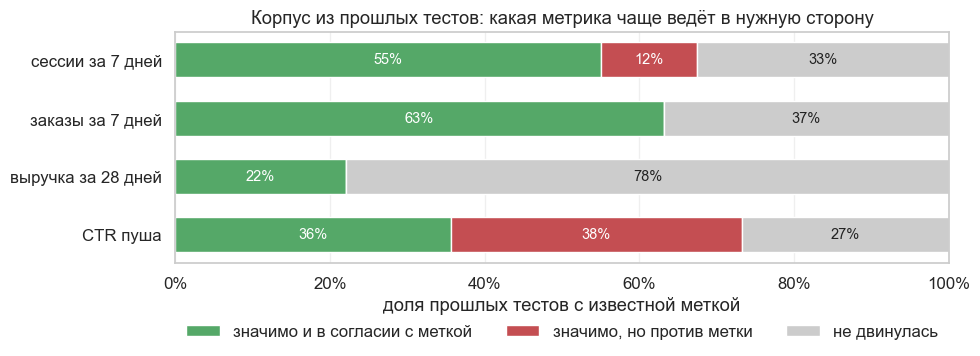

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.9))
order = table.index[::-1]
left = np.zeros(len(order))
for column, color, label in [('согласие с меткой', GREEN, 'значимо и в согласии с меткой'), ('против метки', RED, 'значимо, но против метки'), ('не двинулась', '#CCCCCC', 'не двинулась')]:
    values = table.loc[order, column].values
    ax.barh(order, values, left=left, color=color, label=label, height=.6)
    for position, (value, start) in enumerate(zip(values, left)):
        if value > .07:
            ax.text(start + value / 2, position, f'{100 * value:.0f}%', ha='center', va='center', color='#222222' if color == '#CCCCCC' else 'white', fontsize=10.5)
    left += values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel('доля прошлых тестов с известной меткой')
ax.set_title('Корпус из прошлых тестов: какая метрика чаще ведёт в нужную сторону')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.2), ncol=3, frameon=False)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

In [7]:
spread = pd.concat([corpus_metrics(make_corpus(np.random.default_rng(seed)))['согласие с меткой'].rename(seed) for seed in range(100, 150)], axis=1).T
spread_against = pd.concat([corpus_metrics(make_corpus(np.random.default_rng(seed)))['против метки'].rename(seed) for seed in range(100, 150)], axis=1).T
print('Разброс по 50 корпусам (5-й, 50-й и 95-й перцентили):')
print(pd.DataFrame({'согласие, 5%': spread.quantile(.05), 'согласие, 50%': spread.quantile(.5), 'согласие, 95%': spread.quantile(.95),
                    'против, 50%': spread_against.quantile(.5)}).round(2).to_string())

Разброс по 50 корпусам (5-й, 50-й и 95-й перцентили):
                    согласие, 5%  согласие, 50%  согласие, 95%  против, 50%
метрика                                                                    
сессии за 7 дней            0.55           0.60           0.65         0.12
заказы за 7 дней            0.57           0.63           0.67         0.00
выручка за 28 дней          0.18           0.21           0.25         0.00
CTR пуша                    0.33           0.38           0.43         0.34


Как читать результат.

* **Заказы за 7 дней** значимы в 63% размеченных тестов и ни разу не двигаются против метки. Это лучший из четырёх кандидатов: надёжный OEC.
* **Сессии за 7 дней** чувствительнее (67%), зато в 12% размеченных тестов значимо идут против метки, то есть почти каждый пятый значимый результат ведёт в неверную сторону: их накручивают так же, как в предыдущем разделе. Такая метрика годится как диагностическая, но не как единственная.
* **Выручка за 28 дней** всегда смотрит в правильную сторону, но чувствительность низкая: она значима лишь в 22% тестов. Для неё нужны дольше идущие тесты или методы ускорения из [занятия 1.04](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/04.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D1%8B%20%D1%83%D1%81%D0%BA%D0%BE%D1%80%D0%B5%D0%BD%D0%B8%D1%8F%20AB%20%D1%82%D0%B5%D1%81%D1%82%D0%BE%D0%B2).
* **CTR пуша** значим часто (73%) и при этом врёт: направление совпадает с меткой в 36% размеченных тестов и противоречит ей в 38%, то есть направление случайно. Это типичная локальная метрика, по которой нельзя принимать решения.

Конкретные проценты зависят от того, как мы задали корпус (доля накрутки, шумы), но порядок метрик устойчив: на 50 других корпусах согласие с меткой у заказов за 7 дней остаётся около 57–67%, а у сессий около 55–65% при стабильных 12% против метки. Реальный корпус придётся собирать самим: берут запущенные эксперименты, у которых итог подтвердился отдельной проверкой (долгосрочный holdout, повторный запуск, ручная оценка).

Если корпуса нет, например продукт молодой, остаётся менее надёжный путь: намеренно ухудшить опыт небольшой доле пользователей и посмотреть, заметит ли метрика ухудшение. Про такой подход, помимо корпуса экспериментов, пишут Deng и Shi ([KDD 2016](https://doi.org/10.1145/2939672.2939700)).

## Прокси и суррогаты: одной корреляции мало

Если north star недоступна за время теста, ищут **прокси**: быструю метрику, которая её предсказывает. Типичный способ: посчитать корреляцию между доступными метриками и north star, взять самую коррелированную. Это опасно, и вот почему.

Возьмём заказы за первые 7 дней как кандидата на прокси для заказов за 90 дней. На уровне пользователей связь прекрасная: активные пользователи активны и в первую неделю, и потом.

In [8]:
rng = np.random.default_rng(11)
n_users = 20000
activity = rng.gamma(2.0, .5, n_users)  # скрытая активность пользователя
orders_7d = rng.poisson(3 * activity)
orders_90d = rng.poisson(25 * activity)
user_corr = np.corrcoef(orders_7d, orders_90d)[0, 1]
print(f'Корреляция заказов за 7 и за 90 дней на уровне пользователей: {user_corr:.2f}')

Корреляция заказов за 7 и за 90 дней на уровне пользователей: 0.74


Корреляция высокая (около 0.74), и кажется, что прокси готов. Но решение принимается по **эффекту воздействия**, а не по уровню метрики. Проверим, как связаны эффекты на 7-дневные и 90-дневные заказы по 150 прошлым тестам. Среди них 20% тестов — промо-акции со скидкой: они подтягивают спрос из будущего, то есть быстро поднимают заказы в первую неделю, а за 90 дней дают ноль или минус, потому что пользователи просто купили раньше.

In [9]:
def make_surrogate_tests(rng, n=150, promo_share=.2):
    """Эффекты в % на первые 7 и на 90 дней в прошлых тестах: обычные изменения и промо-акции."""
    promo = rng.random(n) < promo_share
    short = np.where(promo, rng.normal(12, 3, n), rng.normal(0, 3, n))
    long_ = np.where(promo, rng.normal(-1, 1.5, n), .7 * short + rng.normal(0, .8, n))
    return pd.DataFrame({'short': short, 'long': long_, 'promo': promo})


tests = make_surrogate_tests(np.random.default_rng(3))
usual = tests[~tests.promo]
slope, intercept = np.polyfit(usual.short, usual.long, 1)
r2_all = np.corrcoef(tests.short, tests.long)[0, 1] ** 2
r2_usual = np.corrcoef(usual.short, usual.long)[0, 1] ** 2
promo_mean = tests[tests.promo][['short', 'long']].mean()
print(f'R² между эффектами по всем тестам: {r2_all:.2f}')
print(f'R² только по обычным изменениям: {r2_usual:.2f}')
print(f'Для промо линия обычных тестов предсказала бы эффект на 90 дней {intercept + slope * promo_mean.short:+.1f}%, а на деле {promo_mean.long:+.1f}%')

R² между эффектами по всем тестам: 0.08
R² только по обычным изменениям: 0.87
Для промо линия обычных тестов предсказала бы эффект на 90 дней +8.1%, а на деле -1.1%


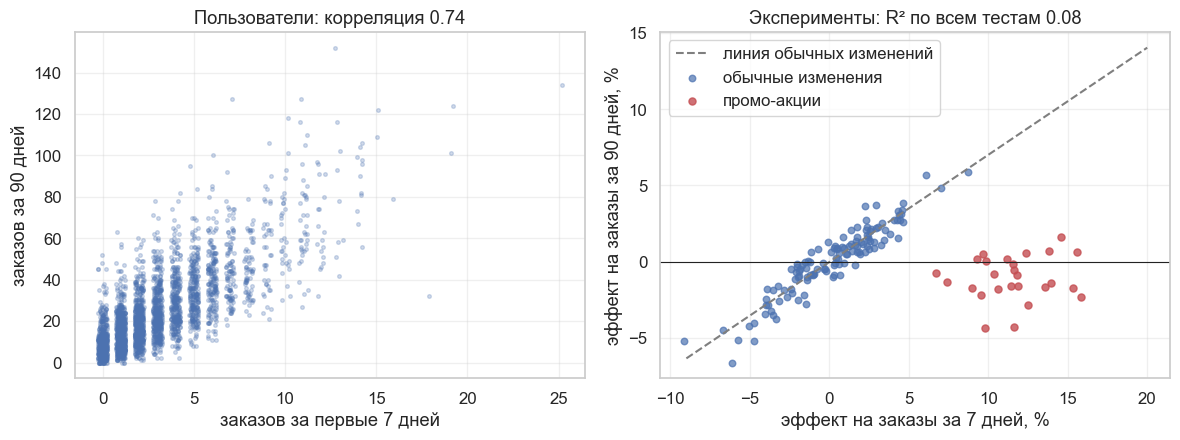

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sample = np.random.default_rng(0).choice(n_users, 3000, replace=False)
axes[0].scatter(orders_7d[sample] + np.random.default_rng(1).uniform(-.25, .25, len(sample)), orders_90d[sample], s=7, alpha=.25, color=BLUE)
axes[0].set_title(f'Пользователи: корреляция {user_corr:.2f}')
axes[0].set_xlabel('заказов за первые 7 дней')
axes[0].set_ylabel('заказов за 90 дней')
grid = np.linspace(-9, 20, 50)
axes[1].plot(grid, intercept + slope * grid, color=GRAY, linestyle='--', label='линия обычных изменений')
axes[1].scatter(usual.short, usual.long, s=22, color=BLUE, alpha=.7, label='обычные изменения')
axes[1].scatter(tests[tests.promo].short, tests[tests.promo].long, s=26, color=RED, alpha=.8, label='промо-акции')
axes[1].axhline(0, color='#222222', linewidth=.8)
axes[1].set_title(f'Эксперименты: R² по всем тестам {r2_all:.2f}')
axes[1].set_xlabel('эффект на заказы за 7 дней, %')
axes[1].set_ylabel('эффект на заказы за 90 дней, %')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

Левый график убеждает, правый показывает, что убеждаться было не в чем. Для обычных изменений эффекты действительно ложатся на линию (R² около 0.87), но по всем тестам R² падает до 0.08: промо-акции лежат в стороне, у них большой эффект на 7 дней (около +12%) и отрицательный на 90 (около −1%), а линия обычных тестов обещала бы им примерно +8%. Если выбрать прокси по корреляции пользователей и принять решение по первой неделе, мы будем уверенно запускать акции, которые не приносят ничего.

Формально суррогат работает, если эффект воздействия на долгий исход **проходит только через суррогат** (условие Прентиса). Промо нарушает его: у акции есть собственный путь к долгому исходу, мимо первой недели. Athey, Chetty, Imbens и Kang ([NBER, 2019](https://nber.org/papers/w26463.pdf)) обобщают идею на несколько суррогатов, оценивают предсказанное значение долгого исхода (суррогатный индекс) и предлагают способы проверять предположения на дополнительных наблюдаемых исходах.

На практике из этого следует несколько правил:

* **Прокси проверяют на уровне экспериментов, а не пользователей.** Нужен корпус прошлых тестов, где известны оба эффекта.
* **Прокси применимы только к типам изменений, на которых они проверены.** Для акций, скидок и всего, что «перетягивает» спрос во времени, нужна отдельная проверка.
* **Несовершенный суррогат раздувает ложные срабатывания.** Duan, Ba и Zhang ([LinkedIn, WSDM 2021](https://arxiv.org/abs/2106.01421)) показывают, что обычный A/B-тест по метрике-суррогату даёт высокую долю ложных срабатываний, потому что суррогат редко идеально предсказывает цель, и предлагают поправки к сравнению.

### Проверьте себя

**Ситуация 2.** Скорость загрузки главной на уровне пользователей коррелирует с числом заказов на 0.9. Аналитик предлагает использовать скорость как прокси для заказов и принимать решения только по ней. В чём риск?

<details>
<summary>Ответ</summary>

Корреляция на уровне пользователей говорит, что быстрые пользователи заказывают больше, но не говорит, что ускорение приложения заставит заказывать больше. Быстрые пользователи могут просто жить в районах с хорошей сетью и высоким доходом. Для прокси нужна связь между **эффектами экспериментов**: на корпусе прошлых тестов проверить, что тесты, ускорявшие приложение, двигали заказы. Кроме того, прокси верно предсказывает только тот тип изменений, на котором проверен: ускорение клиента и новый рекомендательный блок могут влиять на заказы совсем по-разному.
</details>

## Горизонт теста и долгосрочные эффекты

Даже хорошая OEC измеряет эффект за время теста, а он может меняться. Покажем на нашем кейсе с пушами: пользователи сначала реагируют на навязчивые уведомления (эффект новизны), потом устают и отписываются.

Смоделируем 8 недель теста на 100 тысяч пользователей в каждой группе. Недельное число заказов подчиняется пуассоновскому закону, а пуши умножают его интенсивность: эффект +6% в первую неделю постепенно затухает и переходит в −1.5%.

In [11]:
def weekly_effects(rng, n=100000, weeks=8):
    """Относительный эффект пушей на недельные заказы по неделям теста (с 95% ДИ) и объединённый эффект недель 5–8."""
    base = rng.gamma(2.0, .3, n)
    base_t = rng.gamma(2.0, .3, n)
    control, test, rows = [], [], []
    for week in range(weeks):
        multiplier = 1 + (-0.015 + 0.075 * np.exp(-week / 1.3))
        a = rng.poisson(base).astype(float)
        b = rng.poisson(base_t * multiplier).astype(float)
        control.append(a)
        test.append(b)
        effect, se = rel_effect(a, b)
        rows.append({'неделя': week + 1, 'эффект': effect, 'низ': effect - 1.96 * se, 'верх': effect + 1.96 * se, 'истина': multiplier - 1})
    return pd.DataFrame(rows), rel_effect(np.sum(control[4:], axis=0), np.sum(test[4:], axis=0))


weekly, (late_effect, late_se) = weekly_effects(np.random.default_rng(5))
print(weekly.assign(**{c: (100 * weekly[c]).round(1) for c in ['эффект', 'низ', 'верх', 'истина']}).to_string(index=False))
true_late = weekly[weekly['неделя'] >= 5]['истина'].mean()
print(f'\nОбъединённый эффект недель 5–8: {pct(late_effect)} (95% ДИ {pct(late_effect - 1.96 * late_se)}; {pct(late_effect + 1.96 * late_se)}), истина {pct(true_late)}')

 неделя  эффект  низ  верх  истина
      1     6.8  5.5   8.2     6.0
      2     2.3  0.9   3.6     2.0
      3    -1.2 -2.5   0.0     0.1
      4    -0.6 -1.8   0.7    -0.8
      5    -1.5 -2.8  -0.2    -1.2
      6    -1.6 -2.9  -0.3    -1.3
      7    -1.2 -2.4   0.1    -1.4
      8    -1.9 -3.2  -0.7    -1.5

Объединённый эффект недель 5–8: -1.6% (95% ДИ -2.4%; -0.7%), истина -1.3%


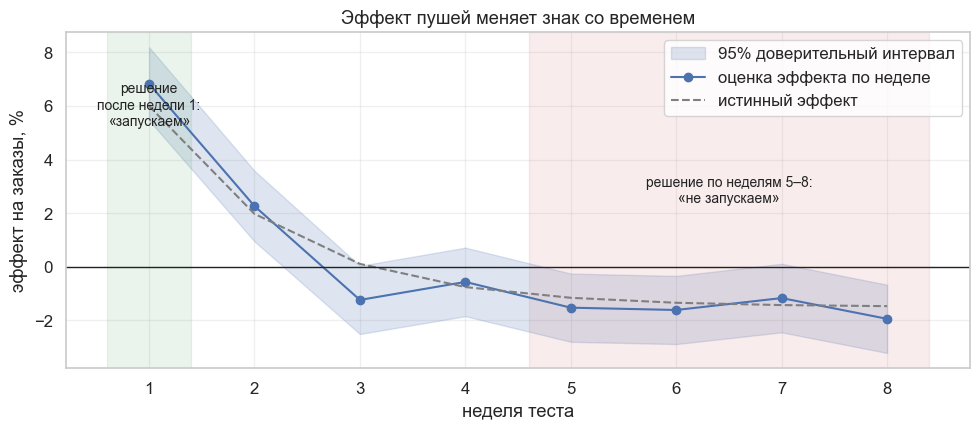

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(weekly['неделя'], 100 * weekly['низ'], 100 * weekly['верх'], color=BLUE, alpha=.18, label='95% доверительный интервал')
ax.plot(weekly['неделя'], 100 * weekly['эффект'], color=BLUE, marker='o', label='оценка эффекта по неделе')
ax.plot(weekly['неделя'], 100 * weekly['истина'], color=GRAY, linestyle='--', label='истинный эффект')
ax.axhline(0, color='#222222', linewidth=1)
ax.axvspan(.6, 1.4, color=GREEN, alpha=.12)
ax.text(1, 6.9, 'решение\nпосле недели 1:\n«запускаем»', ha='center', va='top', fontsize=10, color='#222222')
ax.axvspan(4.6, 8.4, color=RED, alpha=.1)
ax.text(6.5, 3.4, 'решение по неделям 5–8:\n«не запускаем»', ha='center', va='top', fontsize=10, color='#222222')
ax.set_xlabel('неделя теста')
ax.set_ylabel('эффект на заказы, %')
ax.set_title('Эффект пушей меняет знак со временем')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

Решения после первой недели и по неделям 5–8 противоположны: в первую неделю эффект около +7% при интервале примерно от +5.5 до +8, а объединённый эффект недель 5–8 около −1.6% с интервалом от −2.4 до −0.7%. Знак меняется уже к третьей неделе. Если остановить тест на пике новизны, мы запустим вредное изменение.

Против этого работают три приёма.

* **Минимальная длительность** теста, привязанная к циклу поведения пользователей (не меньше полного недельного цикла и до затухания новизны). Как выявлять новизну и эффект ранних пользователей по когортам, разобрано в практике [2.П1](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/2.%20%D0%9A%D0%B2%D0%B0%D0%B7%D0%B8-%D1%8D%D0%BA%D1%81%D0%BF%D0%B5%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%9F%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5).
* **Долгосрочный holdout.** После запуска небольшую долю пользователей (на практике единицы процентов) оставляют на старой версии и месяцами сравнивают с остальными. Так проверяют, не расходится ли долгосрочный эффект с тестовым.
* **Модель долгого эффекта по короткому.** Hohnhold, O'Brien и Tang ([Google, KDD 2015](https://research.google/pubs/focus-on-the-long-term-its-better-for-users-and-business/)) измеряли долгосрочное обучение пользователей на рекламе в поиске: пользователи со временем реже кликают на рекламу после показа некачественной, поэтому рост выручки от большего числа объявлений в краткосрочном тесте оборачивается потерями позже. Они строят модель, предсказывающую долгий эффект по коротким метрикам, и на её основе меняют аукцион.

Эти приёмы работают вместе с прокси из прошлого раздела: прокси проверяют на корпусе, а долгосрочный holdout даёт новые наблюдения для этого корпуса.

### Проверьте себя

**Ситуация 3.** В акции со скидкой за первые три дня теста заказы выросли на 10%, p < 0.001. Продакт просит остановить тест и запускать на всех. Что вы ответите?

<details>
<summary>Ответ</summary>

Нужно понять, не перетянула ли акция спрос из будущего (пользователи просто купили раньше). Для этого продолжаем тест после окончания акции и смотрим эффект по неделям, а также заказы за более длинный горизонт (14 и 28 дней) у тех же пользователей. Дополнительно проверяем, как акция повлияла на маржу и на заказы без скидки: если пользователи привыкли ждать скидку, долгосрочный эффект может быть отрицательным. Решение по первым трём дням не принимаем: рост за короткое окно после промо характерен для переноса спроса, а не для реального роста.
</details>

## Метрика-SRM: когда меняется набор наблюдений

С [SRM](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%A2%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%BD%D0%BE%D0%B2%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D0%B0%D0%BD%D0%B8%D1%86%D1%8B%20%D1%87%D0%B5%D0%BA%D0%B0%D1%83%D1%82%D0%B0.%20AB%20%D1%82%D0%B5%D1%81%D1%82%20%D0%BD%D0%B0%20z%20%D1%82%D0%B5%D1%81%D1%82%D0%B5) на уровне пользователей мы уже знакомы: если доли групп не совпали с планом, тесту нельзя верить. Но у такого же сбоя есть **метрический двойник**. Пользователей в группах поровну, а набор событий, по которым считается метрика, разный. Тогда метрику использовать нельзя.

Классический пример из статьи Dmitriev и др.: в Microsoft на главной странице MSN ссылки начали открывать в новой вкладке. Время загрузки главной выросло на 8.32%. Откуда деградация от одной строчки JavaScript? Оказалось, что в контроле пользователь после перехода по ссылке возвращался кнопкой «назад», и главная перезагружалась. Такие перезагрузки быстрее первой загрузки из-за кэша. В тесте вкладка с главной оставалась открытой, перезагрузок не было, и быстрые загрузки из среднего пропали. Число загрузок главной в тесте было на 7.8% ниже.

Воспроизведём механизм на нашем кейсе. В тесте мы открываем карточку ресторана поверх главной: «назад» не перезагружает главную. Скорость самой главной не менялась совсем.

In [13]:
def simulate_plt(rng, n=20000):
    """Загрузки главной: первая (медленная) и повторные при возврате назад (быстрые, из кэша). Скорость в группах одинакова."""
    data = {}
    for arm, back_rate in (('контроль', 1.0), ('тест', 0.0)):
        first = rng.poisson(5, n)
        back = rng.poisson(back_rate, n)
        loads = first + back
        user_of_load = np.repeat(np.arange(n), loads)
        is_first = np.concatenate([np.r_[np.ones(f, bool), np.zeros(b, bool)] for f, b in zip(first, back)])
        seconds = np.where(is_first, rng.lognormal(np.log(2.0) - .125, .5, loads.sum()), rng.lognormal(np.log(1.0) - .125, .5, loads.sum()))
        data[arm] = dict(loads=loads, first=first, total=np.bincount(user_of_load, seconds, n), total_first=np.bincount(user_of_load, seconds * is_first, n))
    return data


def plt_effects(seed):
    data = simulate_plt(np.random.default_rng(seed))
    c, t = data['контроль'], data['тест']
    return (ratio_effect(c['total'], c['loads'], t['total'], t['loads']), rel_effect(c['loads'].astype(float), t['loads'].astype(float)),
            ratio_effect(c['total_first'], c['first'], t['total_first'], t['first']))


avg_all, loads_eff, avg_first = plt_effects(0)
print(f'Среднее время загрузки на одну загрузку: {pct(avg_all[0])} (SE {100 * avg_all[1]:.1f} п.п.)')
print(f'Число загрузок на пользователя:          {pct(loads_eff[0])} (SE {100 * loads_eff[1]:.1f} п.п.)')
print(f'Время только первых загрузок:            {pct(avg_first[0])} (SE {100 * avg_first[1]:.1f} п.п.)')
repeats = [plt_effects(seed) for seed in range(100, 110)]
print('\nРазброс по 10 повторам: среднее время на загрузку от {} до {}, время первых загрузок от {} до {}'.format(
    pct(min(r[0][0] for r in repeats)), pct(max(r[0][0] for r in repeats)), pct(min(r[2][0] for r in repeats)), pct(max(r[2][0] for r in repeats))))

Среднее время загрузки на одну загрузку: +9.0% (SE 0.3 п.п.)
Число загрузок на пользователя:          -16.3% (SE 0.4 п.п.)
Время только первых загрузок:            -0.1% (SE 0.2 п.п.)



Разброс по 10 повторам: среднее время на загрузку от +8.7% до +9.6%, время первых загрузок от -0.4% до +0.3%


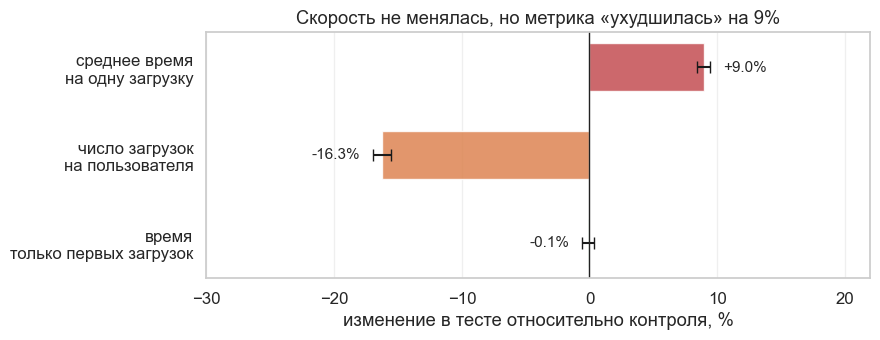

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = ['среднее время\nна одну загрузку', 'число загрузок\nна пользователя', 'время\nтолько первых загрузок']
effects = [avg_all, loads_eff, avg_first]
colors = [RED, ORANGE, GREEN]
for k, ((effect, se), color) in enumerate(zip(effects, colors)):
    ax.barh(k, 100 * effect, xerr=196 * se, color=color, alpha=.85, height=.55, capsize=4)
    ax.text(100 * effect + np.sign(effect) * (196 * se + 1.0), k, pct(effect), va='center', ha='left' if effect > 0 else 'right', fontsize=11)
ax.axvline(0, color='#222222', linewidth=1)
ax.set_yticks(range(3))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlim(-30, 22)
ax.set_xlabel('изменение в тесте относительно контроля, %')
ax.set_title('Скорость не менялась, но метрика «ухудшилась» на 9%')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Метрика «среднее время на загрузку» показывает значимое ухудшение, хотя скорость не менялась: это следствие того, что из выборки исчезли быстрые повторные загрузки (число загрузок на пользователя упало на 16%). Если же сравнить только первые загрузки, разницы нет. На 10 повторах эффект на среднее время на загрузку лежит между +8.7% и +9.6%, а на первые загрузки между −0.4% и +0.3% (истинная разница равна нулю по построению).

Как заметить такое заранее:

* **Всегда смотреть на числитель и знаменатель ratio-метрики отдельно.** Статья советует считать оба как count-метрики и показывать вместе с отношением.
* **Проверять знаменатель так же, как SRM:** значимо ли отличается число событий (загрузок, показов, сессий) на пользователя. Значимое отличие означает, что набор наблюдений в группах разный и ratio сравнивать нельзя.
* **Если набор разный, искать подвыборку, которая сравнима по построению.** Здесь это первые загрузки.

Авторы статьи также советуют по умолчанию считать ratio-метрику как среднее отношений по пользователям, а не как отношение сумм: так знаменатель равен числу пользователей, которое контролируется экспериментом, и риск метрического SRM ниже, к тому же такую метрику проще анализировать и она устойчивее к выбросам. Но когда меняется набор наблюдений внутри самого пользователя, как в примере выше, это не спасает.

Причины метрического SRM бывают разные: изменение поведения (как здесь), разная потеря телеметрии, ошибка в разметке событий. Поэтому метрики с подозрением на SRM нельзя ни интерпретировать, ни использовать как guardrail.

## Ratio-метрики: числитель и знаменатель по отдельности

Похожая ловушка в CTR. В той же статье в Microsoft блок на главной MSN подняли выше, чтобы до него надо было меньше прокручивать. CTR блока упал на 40%. Оказалось, что клики по блоку выросли на 74%, а показы блока на 200%: знаменатель вырос сильнее числителя. CTR всей страницы при этом не изменился, а выручка выросла, потому что продвинутый блок монетизируется лучше. Эксперимент был хорошим, а CTR блока выглядел катастрофой.

В нашем кейсе то же самое случится, если блок «Акции» поднять выше на экране.

In [15]:
def simulate_module_ctr(rng, n=40000):
    """Блок «Акции» на главной: в тесте его видят чаще, а в среднем он кликабелен хуже. Клики по остальным блокам частично уходят в акции."""
    rows = {}
    for arm, shows, ctr, other in (('контроль', 2.0, .10, 1.80), ('тест', 6.0, .062, 1.63)):
        impressions = rng.poisson(shows, n)
        clicks = rng.binomial(impressions, ctr)
        other_clicks = rng.poisson(other, n)
        rows[arm] = dict(impr=impressions, clicks=clicks, page_clicks=clicks + other_clicks)
    return rows


module = simulate_module_ctr(np.random.default_rng(2))
c, t = module['контроль'], module['тест']
ctr_eff = ratio_effect(c['clicks'], c['impr'], t['clicks'], t['impr'])
clicks_eff = rel_effect(c['clicks'].astype(float), t['clicks'].astype(float))
impr_eff = rel_effect(c['impr'].astype(float), t['impr'].astype(float))
page_eff = rel_effect(c['page_clicks'].astype(float), t['page_clicks'].astype(float))
effects = pd.DataFrame({'метрика': ['CTR блока (клики / показы)', 'клики по блоку на пользователя', 'показы блока на пользователя', 'клики по всей странице на пользователя'],
                        'эффект': [ctr_eff[0], clicks_eff[0], impr_eff[0], page_eff[0]], 'SE': [ctr_eff[1], clicks_eff[1], impr_eff[1], page_eff[1]]})
print(effects.assign(**{'эффект': effects['эффект'].map(pct), 'SE': (100 * effects['SE']).round(1)}).to_string(index=False))

                               метрика  эффект  SE
            CTR блока (клики / показы)  -37.7% 0.8
        клики по блоку на пользователя  +87.1% 2.6
          показы блока на пользователя +200.4% 1.2
клики по всей странице на пользователя   +0.4% 0.5


Числитель (клики) вырос, знаменатель (показы) вырос ещё сильнее, и отношение упало. Часть кликов у блока «Акции» отняли другие блоки, поэтому клики по всей странице почти не изменились. Интерпретация CTR как «блок стал хуже» не работает, когда меняется число показов или набор пользователей, которые блок видели. Решение нужно принимать по OEC (заказам, выручке), а CTR использовать как диагностическую метрику, которую читают вместе с её числителем и знаменателем.

## Потеря телеметрии

Клиентские события приходят на сервер не все: мобильное приложение копит их в буфере и отправляет пачкой при подходящей сети, а если буфер переполняется, старые события теряются. Если потеря в группах разная, метрики на клиентских событиях смещены.

Так было в эксперименте Skype из той же статьи: новый протокол пушей оставлял приложение «проснувшимся» на пару секунд дольше, этого хватало, чтобы чаще успеть отправить буфер. В тесте потеряно было меньше событий, и звонковые метрики значимо изменились, хотя звонки эксперимент затрагивать не должен был. Метрики двигались непохоже на обычное улучшение или ухудшение: одни сильно, а связанные с ними не двигались вовсе.

Моделируем: в нашем кейсе изменили способ доставки событий. Реальное число заказов не изменилось, но в тесте теряется 20% клиентских событий вместо 35%.

In [16]:
def simulate_telemetry(rng, n=20000, loss=(.35, .20)):
    """Реальные заказы одинаковы в группах; клиентский лог теряет часть событий, потеря в группах разная."""
    rows = {}
    for arm, rate in zip(('контроль', 'тест'), loss):
        true_orders = rng.poisson(3, n)
        logged = rng.binomial(true_orders, 1 - rate)
        rows[arm] = dict(server=true_orders, client=logged)
    return rows


tele = simulate_telemetry(np.random.default_rng(4))
c, t = tele['контроль'], tele['тест']
client_eff = rel_effect(c['client'].astype(float), t['client'].astype(float))
server_eff = rel_effect(c['server'].astype(float), t['server'].astype(float))
users_with = [np.mean(x['client'] > 0) for x in (c, t)]
chi = st.chi2_contingency([[np.sum(x['client'] > 0), np.sum(x['client'] == 0)] for x in (c, t)])
print(f'Заказы на пользователя по клиентскому логу: {pct(client_eff[0])} (SE {100 * client_eff[1]:.1f} п.п.)')
print(f'Заказы на пользователя на сервере:          {pct(server_eff[0])} (SE {100 * server_eff[1]:.1f} п.п.)')
print(f'Доля пользователей хотя бы с одним клиентским заказом: {100 * users_with[0]:.1f}% и {100 * users_with[1]:.1f}%, p = {chi[1]:.1e}')

Заказы на пользователя по клиентскому логу: +22.9% (SE 0.8 п.п.)
Заказы на пользователя на сервере:          +0.5% (SE 0.6 п.п.)
Доля пользователей хотя бы с одним клиентским заказом: 86.3% и 91.1%, p = 1.4e-51


По клиентскому логу тест «поднял» заказы на 23%, а на сервере разницы нет (+0.5% при стандартной ошибке 0.6 п.п.). Заметить это помогают три проверки.

* **Сверка клиентских событий с серверными** (при возможности). Клиентский лог может терять и дублировать события, а сервер фиксирует каждую оплату.
* **Метрики качества данных:** доля пользователей, у которых вообще есть хоть одно событие, и число событий на пользователя в группах. Здесь они значимо различаются: хотя бы одно клиентское событие есть у 86% пользователей в контроле и у 91% в тесте.
* **Непохожий узор.** Если одни метрики двигаются сильно, а связанные с ними нет, подозрение падает на измерение, а не на поведение.

Телеметрия, на которой потеря различается, делает практически недействительными все метрики, посчитанные по затронутым событиям.

## Триггеринг и разбавление эффекта

Часто изменение касается только части пользователей. Новый баннер «бесплатная доставка от 700 ₽» видят те, у кого в корзине от 500 до 699 ₽, а это 8% пользователей. Если считать эффект по всем, он разбавлен: остальные 92% не изменились, и шум от них только мешает.

Отсюда идея **анализа по триггеру**: сравнивать только тех, кого изменение могло затронуть. Это повышает мощность, но работает при условии: **триггер должен определяться одинаково в обеих группах**, то есть в контроле нужно логировать «пользователь попал бы под баннер». Иначе сравнивают несравнимое.

Сравним три способа анализа на симуляции: по всем пользователям (ITT), по триггеру в обеих группах и неправильный, где в тесте триггером считается «увидел баннер» (а это зависит от поведения после назначения: баннер видят те, кто дошёл до него в интерфейсе, а таких среди активных больше), а в контроле просто «подходил под условия». Истинный эффект баннера на конверсию среди затронутых +4 п.п.

In [17]:
def trigger_trial(rng, n=40000, effect=.04, trigger_rate=.08):
    """Один A/B: в обеих группах n пользователей, затронуты 8% (корзина 500–699 ₽). Вовлечённые среди них конвертируются лучше."""
    arm = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    eligible = rng.random(2 * n) < trigger_rate
    engaged = rng.random(2 * n) < .6
    base = np.where(eligible, np.where(engaged, .46, .31), .12)
    converted = (rng.random(2 * n) < base + effect * (eligible & arm)).astype(float)
    control, test = converted[~arm], converted[arm]
    seen = (eligible & engaged)[arm]
    return {'itt': diff_p(control, test), 'trigger': diff_p(control[eligible[~arm]], test[eligible[arm]]),
            'wrong': diff_p(control[eligible[~arm]], test[seen]), 'share': eligible[arm].mean()}


def trigger_summary(effect, reps=300):
    trials = [trigger_trial(np.random.default_rng(seed), effect=effect) for seed in range(reps)]
    out = {}
    for key in ('itt', 'trigger', 'wrong'):
        deltas = np.array([t[key][0] for t in trials])
        pvalues = np.array([t[key][2] for t in trials])
        out[key] = (deltas.mean(), (pvalues < .05).mean())
    return out


null_case, effect_case = trigger_summary(0.0), trigger_summary(.04)
names = {'itt': 'по всем пользователям', 'trigger': 'по триггеру в обеих группах', 'wrong': 'неправильный триггер'}
table = pd.DataFrame({
    'оценка при нулевом эффекте, п.п.': {names[k]: 100 * v[0] for k, v in null_case.items()},
    'доля значимых при нулевом эффекте': {names[k]: v[1] for k, v in null_case.items()},
    'оценка при эффекте 4 п.п. среди затронутых, п.п.': {names[k]: 100 * v[0] for k, v in effect_case.items()},
    'доля значимых при эффекте': {names[k]: v[1] for k, v in effect_case.items()},
})
print(table.round(3).to_string())

                             оценка при нулевом эффекте, п.п.  доля значимых при нулевом эффекте  оценка при эффекте 4 п.п. среди затронутых, п.п.  доля значимых при эффекте
по всем пользователям                                   0.016                              0.050                                             0.335                      0.277
по триггеру в обеих группах                             0.100                              0.060                                             4.088                      0.903
неправильный триггер                                    6.095                              0.993                                            10.097                      1.000


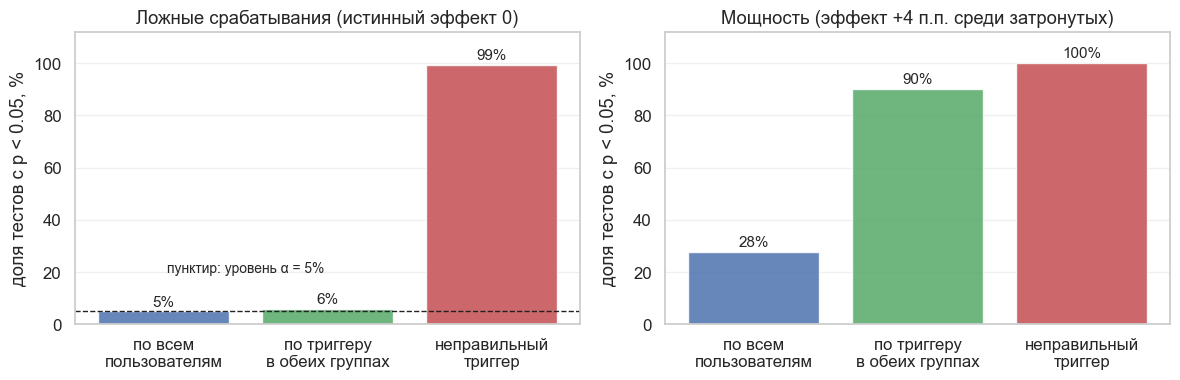

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
labels = ['по всем\nпользователям', 'по триггеру\nв обеих группах', 'неправильный\nтриггер']
colors = [BLUE, GREEN, RED]
for ax, case, title in ((axes[0], null_case, 'Ложные срабатывания (истинный эффект 0)'), (axes[1], effect_case, 'Мощность (эффект +4 п.п. среди затронутых)')):
    values = [100 * case[k][1] for k in ('itt', 'trigger', 'wrong')]
    ax.bar(labels, values, color=colors, alpha=.85)
    for k, value in enumerate(values):
        ax.text(k, value + 2, f'{value:.0f}%', ha='center', fontsize=11)
    ax.set_ylim(0, 112)
    ax.set_ylabel('доля тестов с p < 0.05, %')
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
axes[0].text(.5, 20, 'пунктир: уровень α = 5%', ha='center', fontsize=10)
plt.tight_layout()
plt.show()

Три вывода.

* **Анализ по всем пользователям честен, но слаб:** уровень значимости держит (5%), но при эффекте, разбавленном в 12 раз, находит его лишь в 28% тестов.
* **Анализ по триггеру с одинаковым определением в группах** тоже держит уровень значимости (6%) и находит эффект в 90% тестов.
* **Неправильный триггер ломает всё:** он «находит» эффект в 99% тестов, даже когда его нет (среднюю оценку +6 п.п. при нулевом эффекте). Условие «увидел баннер» зависит от поведения после назначения, поэтому в тесте остаются самые вовлечённые, и разницу создаёт отбор, а не баннер.

Чтобы пересчитать эффект на триггерной подвыборке в эффект на всех пользователей, нужна **формула разбавления** (Deng, Hu, [WSDM 2015](https://exp-platform.com/dilution/)). Для аддитивной user-level метрики, например конверсии, и в предположении, что на незатронутых пользователей эффекта нет, она проста: Δ_overall = Δ_trigger × N_trigger / N. Для ratio-метрик нужны дополнительные множители, и авторы предупреждают, что на практике часто применяют приближённые или неверные формулы. Они предлагают объединить оценку по триггеру и пересчёт в один анализ, что даёт несмещённую оценку общего эффекта с большей мощностью.

In [19]:
trial = trigger_trial(np.random.default_rng(21))
delta_tr, se_tr, _ = trial['trigger']
delta_itt, se_itt, _ = trial['itt']
share = trial['share']
print(f'Доля затронутых: {100 * share:.1f}%')
print(f'Эффект по триггеру: {100 * delta_tr:+.2f} п.п. (95% ДИ {100 * (delta_tr - 1.96 * se_tr):+.2f}; {100 * (delta_tr + 1.96 * se_tr):+.2f})')
print(f'Разбавленный на всех (Δ × доля): {100 * delta_tr * share:+.2f} п.п. (95% ДИ {100 * (delta_tr - 1.96 * se_tr) * share:+.2f}; {100 * (delta_tr + 1.96 * se_tr) * share:+.2f})')
print(f'Прямая оценка по всем:           {100 * delta_itt:+.2f} п.п. (95% ДИ {100 * (delta_itt - 1.96 * se_itt):+.2f}; {100 * (delta_itt + 1.96 * se_itt):+.2f})')

Доля затронутых: 7.9%
Эффект по триггеру: +2.92 п.п. (95% ДИ +0.48; +5.35)
Разбавленный на всех (Δ × доля): +0.23 п.п. (95% ДИ +0.04; +0.42)
Прямая оценка по всем:           +0.08 п.п. (95% ДИ -0.41; +0.57)


Истинный эффект на всех пользователей равен 0.04 × 0.08 = 0.32 п.п. Обе оценки с ним согласуются, но интервал разбавленной оценки примерно в 2.6 раза уже прямого: именно в этом выигрыш триггера. Использовать его честно можно, только если мы заранее логируем условие триггера для обеих групп и определяем его по данным **до назначения** (или по признакам, на которые воздействие повлиять не может).

### Проверьте себя

**Ситуация 4.** В тесте 50/50 SRM нет. Метрика «среднее число заказов на активного пользователя» упала на 5%, а число заказов на пользователя не изменилось. Что проверить в первую очередь?

<details>
<summary>Ответ</summary>

«Активный пользователь» определяется поведением после назначения: это тот, кто сделал хотя бы одно действие. Если изменение повлияло на то, сколько пользователей стали активными (например, новые слабоактивные пользователи начали заходить), знаменатель меняется, и метрика сравнивает разные наборы людей. Проверяем число активных пользователей в группах (метрический SRM), смотрим числитель и знаменатель отдельно и опираемся на метрику, посчитанную на всех пользователях, которым назначено воздействие.
</details>

## Парадокс Симпсона: меняющиеся доли

Тест часто запускают постепенно: сначала на малой доле трафика, потом шире, чтобы ограничить ущерб от возможного бага. Но если доля теста меняется во времени, а поведение пользователей тоже меняется во времени (будни и выходные, акции, сезон), общий итог по периоду может показать **обратный** знак по сравнению с каждым днём. Это парадокс Симпсона. Crook, Frasca, Kohavi и Longbotham ([KDD 2009](https://exp-platform.com/seven-pitfalls/)) называют его среди ловушек, которые они встречали при запуске экспериментов в вебе: при постепенном росте доли теста легко выбрать неправильного победителя.

Наш случай. Неделя теста: в будни тест получает 50% трафика, а в выходные его, из осторожности перед пиком, снижают до 10%. В выходные конверсия выше. Тест на самом деле **повышает** конверсию на 1 п.п. в любой день.

In [20]:
def simulate_ramp(rng, daily=30000, effect=.01):
    """Неделя теста: конверсия и доля теста зависят от дня; истинный эффект теста +1 п.п. каждый день."""
    days = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
    base = [.08] * 5 + [.14] * 2
    share = [.5] * 5 + [.1] * 2
    rows = []
    for day, b, s in zip(days, base, share):
        n_test = rng.binomial(daily, s)
        n_ctrl = daily - n_test
        rows.append({'день': day, 'доля теста': s, 'n_контроль': n_ctrl, 'n_тест': n_test,
                     'конверсия_контроль': rng.binomial(n_ctrl, b) / n_ctrl, 'конверсия_тест': rng.binomial(n_test, b + effect) / n_test})
    return pd.DataFrame(rows)


ramp = simulate_ramp(np.random.default_rng(0))
conv_ctrl = (ramp['конверсия_контроль'] * ramp['n_контроль']).sum() / ramp['n_контроль'].sum()
conv_test = (ramp['конверсия_тест'] * ramp['n_тест']).sum() / ramp['n_тест'].sum()
daily_delta = ramp['конверсия_тест'] - ramp['конверсия_контроль']
daily_var = ramp['конверсия_контроль'] * (1 - ramp['конверсия_контроль']) / ramp['n_контроль'] + ramp['конверсия_тест'] * (1 - ramp['конверсия_тест']) / ramp['n_тест']
weights = 1 / daily_var
stratified = (weights * daily_delta).sum() / weights.sum()
stratified_se = np.sqrt(1 / weights.sum())
pooled_delta = conv_test - conv_ctrl
pooled_se = np.sqrt(conv_ctrl * (1 - conv_ctrl) / ramp['n_контроль'].sum() + conv_test * (1 - conv_test) / ramp['n_тест'].sum())
print(ramp.assign(**{'разница, п.п.': (100 * daily_delta).round(2)}).round(4).to_string(index=False))
print(f'\nОбщий итог за неделю: контроль {100 * conv_ctrl:.2f}%, тест {100 * conv_test:.2f}%, разница {100 * pooled_delta:+.2f} п.п. (SE {100 * pooled_se:.2f})')
print(f'С учётом дня (дни взвешены по точности): {100 * stratified:+.2f} п.п. (SE {100 * stratified_se:.2f}), истина +1.00')

день  доля теста  n_контроль  n_тест  конверсия_контроль  конверсия_тест  разница, п.п.
  Пн         0.5       14892   15108              0.0802          0.0904           1.02
  Вт         0.5       15040   14960              0.0791          0.0907           1.17
  Ср         0.5       14851   15149              0.0810          0.0899           0.89
  Чт         0.5       15016   14984              0.0812          0.0922           1.09
  Пт         0.5       14951   15049              0.0825          0.0874           0.48
  Сб         0.1       26957    3043              0.1389          0.1623           2.34
  Вс         0.1       26951    3049              0.1421          0.1456           0.35

Общий итог за неделю: контроль 10.58%, тест 9.49%, разница -1.09 п.п. (SE 0.13)
С учётом дня (дни взвешены по точности): +0.96 п.п. (SE 0.14), истина +1.00


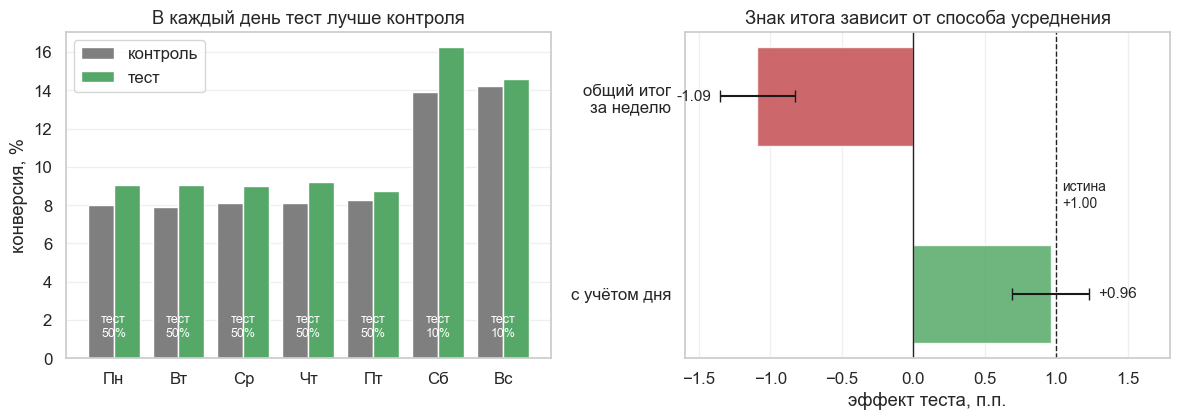

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
x = np.arange(7)
axes[0].bar(x - .2, 100 * ramp['конверсия_контроль'], width=.4, color=GRAY, label='контроль')
axes[0].bar(x + .2, 100 * ramp['конверсия_тест'], width=.4, color=GREEN, label='тест')
for k, s in enumerate(ramp['доля теста']):
    axes[0].text(k, 1, f'тест\n{100 * s:.0f}%', ha='center', va='bottom', fontsize=9, color='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(ramp['день'])
axes[0].set_ylabel('конверсия, %')
axes[0].set_title('В каждый день тест лучше контроля')
axes[0].legend(loc='upper left')
axes[0].grid(axis='x', visible=False)
estimates = [('общий итог\nза неделю', pooled_delta, pooled_se, RED), ('с учётом дня', stratified, stratified_se, GREEN)]
for k, (name, value, se, color) in enumerate(estimates):
    axes[1].barh(k, 100 * value, xerr=196 * se, color=color, alpha=.85, height=.5, capsize=4)
    axes[1].text(100 * value + np.sign(value) * (196 * se + .06), k, f'{100 * value:+.2f}', va='center', ha='left' if value > 0 else 'right', fontsize=11)
axes[1].axvline(1.0, color='#222222', linestyle='--', linewidth=1)
axes[1].text(1.04, .5, 'истина\n+1.00', fontsize=10, va='center')
axes[1].set_xlim(-1.6, 1.8)
axes[1].axvline(0, color='#222222', linewidth=1)
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels([e[0] for e in estimates])
axes[1].invert_yaxis()
axes[1].set_xlabel('эффект теста, п.п.')
axes[1].set_title('Знак итога зависит от способа усреднения')
axes[1].grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Тест стал выглядеть вредным (общий итог −1.09 п.п. при стандартной ошибке 0.13): в нём слишком много будней, когда конверсия низкая, и слишком мало выходных, когда она высокая. С учётом дня оценка +0.96 п.п. при истинных +1.00. Разница между группами в итоге складывается из эффекта теста **и разной структуры дней**. В каждый отдельный день тест лучше контроля.

Как с этим жить:

* **Не менять долю теста по ходу, если можно.** Лучше подбирать фиксированную долю и держать её весь тест.
* **Если долю всё же меняют, анализировать с учётом периода:** считать эффект внутри каждого периода с постоянной долей и объединять (например, взвешивая по точности, как выше, или регрессией с фиксированными эффектами дня). Тогда структура дней уходит из сравнения.
* **Проверять SRM по периодам.** Если доля менялась, суммарная доля групп за весь тест не равна плановой, и обычная проверка SRM по тесту целиком даст ложную тревогу. Её нужно делать внутри каждого периода с постоянной долей.

## Сегменты: скрытая множественность и сегмент, зависящий от воздействия

Результат хочется разрезать: по платформе, городу, давности пользователя. Разрезы полезны для отладки и поиска неоднородности эффекта, но у них три ловушки.

**Первая: множественность.** Если смотреть 20 сегментов, значимый хотя бы в одном найдётся с вероятностью около 64% даже при нулевом эффекте. Покажем на A/A-тесте с 20 сегментами по 4000 пользователей в группе.

In [22]:
def aa_segments(rng, reps=1000, segments=20, n=4000, p=.10):
    """A/A: доля тестов, где хотя бы один сегмент значим без поправки и после поправки Холма."""
    any_raw, any_holm = 0, 0
    for _ in range(reps):
        a, b = rng.binomial(n, p, segments), rng.binomial(n, p, segments)
        pooled = (a + b) / (2 * n)
        z = (b - a) / n / np.sqrt(2 * pooled * (1 - pooled) / n)
        pvalues = 2 * st.norm.sf(np.abs(z))
        any_raw += (pvalues < .05).any()
        ordered = np.sort(pvalues)
        any_holm += ordered[0] <= .05 / segments  # Холм отвергает хоть одну гипотезу, только если min p ≤ α/m
    return any_raw / reps, any_holm / reps


aa_raw, aa_holm = aa_segments(np.random.default_rng(1))
print(f'Хотя бы один значимый из 20 сегментов в A/A: без поправки {100 * aa_raw:.0f}%, с поправкой Холма {100 * aa_holm:.1f}%')

Хотя бы один значимый из 20 сегментов в A/A: без поправки 65%, с поправкой Холма 5.5%


Без поправки «находка» есть в двух тестах из трёх, с поправкой ложных срабатываний около 5%. Сегменты, которые мы будем смотреть, нужно **заранее перечислить** и считать единым семейством гипотез (см. [занятие 1.03](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/03.%20%D0%9C%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B5%D0%BD%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7)).

**Вторая ловушка: «значимо здесь, не значимо там» ничего не говорит о разнице эффектов.** Допустим, у iOS 40 тысяч пользователей в группе, у Android 10 тысяч, а истинный эффект везде одинаков: +0.8 п.п. к конверсии 10%. Мощности у сегментов разные, поэтому часто значим только iOS. Но вывод «на Android не работает» неверен. Правильно проверять **взаимодействие**: значимо ли отличаются эффекты в сегментах.

In [23]:
def significant_here_not_there(rng, reps=3000, p=.10, effect=.008, sizes=(40000, 10000)):
    """Эффект одинаков в двух сегментах. Как часто значим только в первом и как часто значимо взаимодействие."""
    only_first, interaction, only_first_and_interaction = 0, 0, 0
    for _ in range(reps):
        deltas, ses = [], []
        for n in sizes:
            a, b = rng.binomial(n, p), rng.binomial(n, p + effect)
            deltas.append((b - a) / n)
            ses.append(np.sqrt(2 * p * (1 - p) / n))
        significant = [abs(d / s) > 1.96 for d, s in zip(deltas, ses)]
        inter = abs((deltas[0] - deltas[1]) / np.hypot(*ses)) > 1.96
        interaction += inter
        if significant[0] and not significant[1]:
            only_first += 1
            only_first_and_interaction += inter
    return only_first / reps, interaction / reps, only_first_and_interaction / max(only_first, 1)


only_first, inter_all, inter_in_only_first = significant_here_not_there(np.random.default_rng(2))
print(f'Значим только iOS (не значим Android): {100 * only_first:.0f}% тестов')
print(f'Взаимодействие значимо: {100 * inter_all:.1f}% тестов при истинном отсутствии взаимодействия')
print(f'Среди тестов «только iOS» взаимодействие значимо в {100 * inter_in_only_first:.1f}%')

Значим только iOS (не значим Android): 48% тестов
Взаимодействие значимо: 5.1% тестов при истинном отсутствии взаимодействия
Среди тестов «только iOS» взаимодействие значимо в 4.7%


Половина тестов даёт картину «работает на iOS, на Android не работает», хотя эффекты равны. Проверка на взаимодействие почти никогда не подтверждает разницу, и это правильно: данных для такого вывода просто нет. В задаче «катим только на Android» нужно смотреть на разницу эффектов и её доверительный интервал.

**Третья ловушка: сегмент определён по признаку, на который влияет воздействие.** В примере из статьи Microsoft: в Bing разрезали пользователей на тех, кто увидел «глубокие ссылки» в выдаче, и тех, кто не увидел. В обоих сегментах число сессий на пользователя значимо выросло, а в целом по тесту осталось прежним. Эксперимент на сессии не влиял, но он изменил, кто попадает в сегмент: менее активные пользователи выпали из первого сегмента во второй, и в обоих средняя активность выросла.

Воспроизведём механизм. В нашем кейсе сегмент «видит блок рекомендаций» зависит от активности, а тест сместил порог: умеренно активные пользователи перестали его видеть. Сессии никак не менялись.

In [24]:
def post_treatment_segments(rng, n=60000):
    """Сессии не меняются, но тест меняет состав сегмента «видит блок»: умеренно активные пользователи в тесте его не видят."""
    activity = rng.gamma(2.0, 1.0, 2 * n)
    arm = np.r_[np.zeros(n), np.ones(n)].astype(bool)
    sees = np.where(arm, activity > 3.0, activity > 2.2)
    sessions = rng.poisson(activity).astype(float)
    rows = []
    for name, mask in (('видят блок', sees), ('не видят блок', ~sees), ('все пользователи', np.ones(2 * n, bool))):
        a, b = sessions[~arm & mask], sessions[arm & mask]
        effect, se = rel_effect(a, b)
        rows.append({'сегмент': name, 'эффект на сессии': effect, 'SE': se, 'доля в контроле': mask[~arm].mean(), 'доля в тесте': mask[arm].mean()})
    share_p = st.chi2_contingency([[sees[~arm].sum(), (~sees[~arm]).sum()], [sees[arm].sum(), (~sees[arm]).sum()]])[1]
    return pd.DataFrame(rows).set_index('сегмент'), share_p


segments, share_p = post_treatment_segments(np.random.default_rng(3))
print(segments.assign(**{'эффект на сессии': segments['эффект на сессии'].map(pct), 'SE': (100 * segments['SE']).round(1),
                         'доля в контроле': (100 * segments['доля в контроле']).round(1), 'доля в тесте': (100 * segments['доля в тесте']).round(1)}).to_string())
print(f'\nПроверка равенства долей сегмента «видят блок» в группах: p {"< 1e-300" if share_p < 1e-300 else "= " + format(share_p, ".1e")}')

                 эффект на сессии   SE  доля в контроле  доля в тесте
сегмент                                                              
видят блок                 +20.6%  0.8             35.6          20.0
не видят блок              +21.7%  0.8             64.4          80.0
все пользователи            -0.9%  0.6            100.0         100.0

Проверка равенства долей сегмента «видят блок» в группах: p < 1e-300


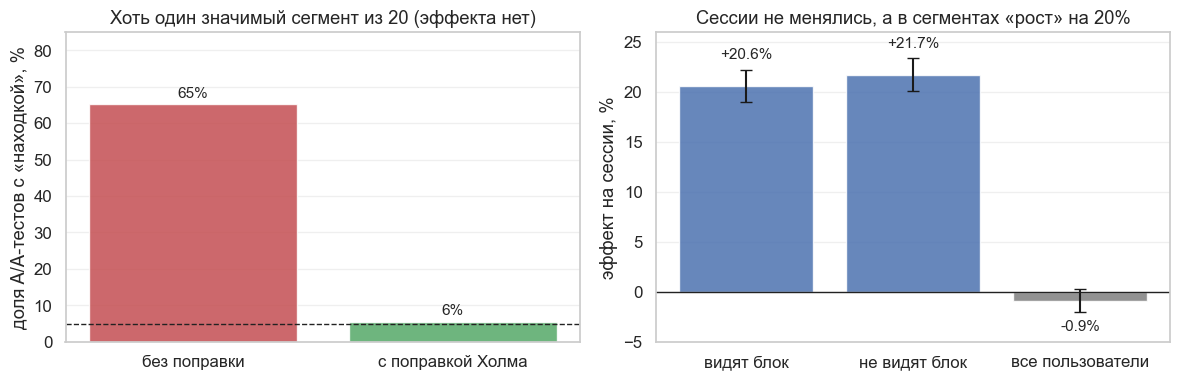

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['без поправки', 'с поправкой Холма'], [100 * aa_raw, 100 * aa_holm], color=[RED, GREEN], alpha=.85)
for k, v in enumerate([100 * aa_raw, 100 * aa_holm]):
    axes[0].text(k, v + 2, f'{v:.0f}%', ha='center', fontsize=11)
axes[0].axhline(5, color='#222222', linestyle='--', linewidth=1)
axes[0].set_ylim(0, 85)
axes[0].set_ylabel('доля A/A-тестов с «находкой», %')
axes[0].set_title('Хоть один значимый сегмент из 20 (эффекта нет)')
axes[0].grid(axis='x', visible=False)
order = segments.index
values = 100 * segments['эффект на сессии']
axes[1].bar(order, values, yerr=196 * segments['SE'], color=[BLUE, BLUE, GRAY], alpha=.85, capsize=4)
for k, (v, se) in enumerate(zip(values, 196 * segments['SE'])):
    axes[1].text(k, v + se + .8 if v >= 0 else v - se - .8, f'{v:+.1f}%', ha='center', va='bottom' if v >= 0 else 'top', fontsize=11)
axes[1].set_ylim(-5, 26)
axes[1].axhline(0, color='#222222', linewidth=1)
axes[1].set_ylabel('эффект на сессии, %')
axes[1].set_title('Сессии не менялись, а в сегментах «рост» на 20%')
axes[1].grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

Оба сегмента показывают рост около 20%, а общий эффект равен нулю: изменился состав сегментов. Лекарство то же, что для SRM, только на уровне сегмента: **проверять, что доля пользователей в сегменте одинакова в группах** (здесь p ≈ 0, доля упала с 36% до 20%). Если не одинакова, сегмент определён по признаку, на который воздействие повлияло, и его нельзя использовать для сравнения. Безопасны сегменты по признакам, зафиксированным до назначения (платформа, страна, давность регистрации).

### Проверьте себя

**Ситуация 5.** После теста аналитик сообщает: «на Android эффект значим (p = 0.03), на iOS нет (p = 0.30), запускаем только на Android». Что вы проверите до решения?

<details>
<summary>Ответ</summary>

Первое: значимо ли различие эффектов между платформами. Значим в одном и не значим в другом — не доказательство различия: сегменты могут отличаться только размером и, соответственно, мощностью. Второе: был ли сегмент одним из заранее выбранных или аналитик нашёл его среди многих разрезов (множественность). Третье: одинакова ли доля платформ в группах. Если различия эффектов нет, а платформа запланирована заранее, разумнее запускать на всех и смотреть на объединённый эффект.
</details>

## Неполные воронки

Многие пути пользователя устроены как воронка: открыл корзину, нажал «Оплатить», оплата прошла. Лёгкий способ улучшить метрику на одном шаге — сместить внимание пользователя на него. В Microsoft в экспериментах на Xbox с промо-акциями небольшие изменения картинок и текстов сильно повышали клики по распродаже, но выручка не росла, при том что мощности хватало ([Dmitriev и др., 2017](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf)). Пользователи просто тратили лишнее время.

Поэтому в воронке нужно считать **оба вида метрик по всем шагам**: условные (доля прошедших шаг среди дошедших до него) и безусловные (доля прошедших шаг среди всех, кто начал воронку).

Новая кнопка оплаты в нашем кейсе: она заметнее, на неё нажимают чаще, но платёж проходит реже, потому что часть пользователей жмёт случайно и сдаётся на странице банка.

In [26]:
def simulate_funnel(rng, n=50000):
    """Воронка корзина → клик «Оплатить» → успешная оплата. В тесте клик чаще, а оплата среди кликнувших реже."""
    rows = {}
    for arm, click_rate, success_rate in (('контроль', .50, .85), ('тест', .60, .70)):
        click = rng.random(n) < click_rate
        success = click & (rng.random(n) < success_rate)
        rows[arm] = dict(click=click.astype(float), success=success.astype(float))
    return rows


funnel = simulate_funnel(np.random.default_rng(6))
c, t = funnel['контроль'], funnel['тест']
click_eff = rel_effect(c['click'], t['click'])
cond_eff = rel_effect(c['success'][c['click'] > 0], t['success'][t['click'] > 0])
uncond_eff = rel_effect(c['success'], t['success'])
steps = pd.DataFrame({'шаг': ['клик «Оплатить» (безусловно)', 'оплата среди кликнувших (условно)', 'оплата среди всех (безусловно)'],
                      'контроль': [c['click'].mean(), c['success'][c['click'] > 0].mean(), c['success'].mean()],
                      'тест': [t['click'].mean(), t['success'][t['click'] > 0].mean(), t['success'].mean()],
                      'эффект': [click_eff[0], cond_eff[0], uncond_eff[0]], 'SE': [click_eff[1], cond_eff[1], uncond_eff[1]]})
print(steps.assign(контроль=(100 * steps['контроль']).round(1), тест=(100 * steps['тест']).round(1), эффект=steps['эффект'].map(pct), SE=(100 * steps['SE']).round(1)).to_string(index=False))

                              шаг  контроль  тест эффект  SE
     клик «Оплатить» (безусловно)      50.3  60.5 +20.4% 0.7
оплата среди кликнувших (условно)      84.7  69.5 -18.0% 0.4
   оплата среди всех (безусловно)      42.6  42.0  -1.2% 0.7


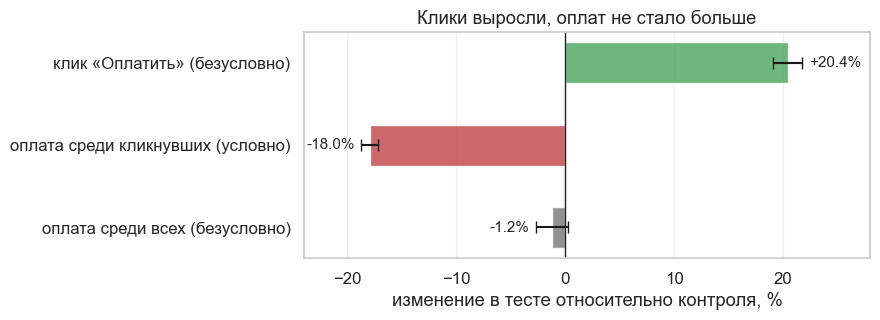

In [27]:
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = [GREEN, RED, GRAY]
for k, (row, color) in enumerate(zip(steps.itertuples(), colors)):
    ax.barh(k, 100 * row.эффект, xerr=196 * row.SE, color=color, alpha=.85, height=.5, capsize=4)
    ax.text(100 * row.эффект + np.sign(row.эффект) * (196 * row.SE + .6), k, pct(row.эффект), va='center', ha='left' if row.эффект > 0 else 'right', fontsize=11)
ax.axvline(0, color='#222222', linewidth=1)
ax.set_yticks(range(3))
ax.set_yticklabels(steps['шаг'])
ax.invert_yaxis()
ax.set_xlim(-24, 28)
ax.set_xlabel('изменение в тесте относительно контроля, %')
ax.set_title('Клики выросли, оплат не стало больше')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

Если смотреть только на клик, тест выигрывает на 20%. Условная метрика показывает причину: среди кликнувших платёж проходит реже на 18%. Безусловная метрика даёт итог: оплат не стало больше (−1.2% при стандартной ошибке 0.7 п.п., то есть в пределах шума). Клик по кнопке остаётся диагностической метрикой и не годится для решения.

## Закон Твайман

Все ловушки выше объединяет одно правило, которое Microsoft формулирует в духе закона Твайман: любое необычное движение метрики, хорошее или плохое, чаще всего означает проблему. Мы склонны скептически смотреть на неожиданный минус и радоваться неожиданному плюсу, а проверять надо оба.

Пример из той же статьи: на главной MSN кнопку Outlook.com заменили на кнопку почтового приложения. Клики по странице выросли на 4.7%, клики по самой кнопке на 28%, и ещё на 27% по соседней. Казалось, что тест превзошёл ожидания. Но метрики удержания и удовлетворённости не изменились, а клики по кнопке быстро падали день ото дня. Пользователи привыкли, что кнопка ведёт на Outlook.com, не понимали, что она открывает другое приложение, и кликали снова и по соседней кнопке тоже. Эксперимент закрыли до конца срока, чтобы не раздражать людей.

В нашем кейсе другой сценарий: ошибка логирования. В новой версии iOS-приложения каждая покупка записывается в клиентский лог дважды. Сам заказ один, на сервере всё в порядке.

In [28]:
def simulate_duplicate_logging(rng, n=30000):
    """Реальных различий нет. В тесте у iOS (40% пользователей) клиент пишет каждую покупку дважды."""
    rows = []
    for arm, doubled in (('контроль', False), ('тест', True)):
        ios = rng.random(n) < .4
        purchases = rng.poisson(.5, n)
        revenue_per_purchase = rng.gamma(4, 120, n)
        server_revenue = purchases * revenue_per_purchase
        multiplier = np.where(ios & doubled, 2, 1)
        rows.append(pd.DataFrame({'arm': arm, 'ios': ios, 'server_purchases': purchases, 'client_purchases': purchases * multiplier,
                                  'server_revenue': server_revenue, 'client_revenue': server_revenue * multiplier}))
    return pd.concat(rows)


dup = simulate_duplicate_logging(np.random.default_rng(8))
rows = []
for column, label in (('client_revenue', 'выручка на пользователя (клиент)'), ('server_revenue', 'выручка на пользователя (сервер)'),
                      ('client_purchases', 'покупок на пользователя (клиент)'), ('server_purchases', 'покупок на пользователя (сервер)')):
    a, b = dup.loc[dup.arm == 'контроль', column], dup.loc[dup.arm == 'тест', column]
    effect, se = rel_effect(a, b)
    rows.append({'метрика': label, 'эффект': pct(effect), 'p-value': f'{diff_p(a, b)[2]:.1e}'})
print(pd.DataFrame(rows).to_string(index=False))
ratio = dup.groupby(['arm', 'ios']).apply(lambda g: g.client_purchases.sum() / g.server_purchases.sum(), include_groups=False).unstack().rename(columns={False: 'Android', True: 'iOS'})
print('\nОтношение клиентских покупок к серверным по платформам:')
print(ratio.round(2).to_string())

                         метрика эффект  p-value
выручка на пользователя (клиент) +39.4% 2.0e-112
выручка на пользователя (сервер)  -0.1%  9.5e-01
покупок на пользователя (клиент) +39.9% 4.7e-157
покупок на пользователя (сервер)  +0.3%  8.3e-01

Отношение клиентских покупок к серверным по платформам:
ios       Android  iOS
arm                   
контроль      1.0  1.0
тест          1.0  2.0


По клиентскому логу тест обещает рост выручки на десятки процентов при заранее ожидаемом эффекте в единицы процентов, а на сервере разницы нет. Подозрение вызывает уже масштаб: эффект в разы превышает всё, что мы закладывали при планировании. Локализуется причина разрезом по платформам и сверкой с сервером: у iOS в тесте клиент пишет ровно вдвое больше событий, чем сервер, а у Android всё сходится.

Практическое правило, которое сэкономит больше всего ошибочных запусков: **чем лучше результат, тем тщательнее его проверять.** Если эффект в разы больше ожидаемого MDE, это повод искать ошибку (логирование, дубли, сегмент по сломанному признаку), а не праздновать.

### Проверьте себя

**Ситуация 6.** В тесте нового экрана клики по главной кнопке выросли на 28%, число заказов не изменилось, а эффект по дням быстро убывает. Что вы скажете команде?

<details>
<summary>Ответ</summary>

Рост кликов без роста заказов и быстро затухающий эффект указывают, что клики вызваны не интересом, а новизной или путаницей: кнопка ведёт не туда, куда привыкли пользователи, и они кликают повторно, как в примере MSN. Решение по кликам принимать нельзя. Смотрим OEC и guardrail-метрики (удержание, отписки, жалобы), анализируем эффект по дням и когортам, проверяем, нет ли роста повторных кликов у одних и тех же пользователей. Если OEC не изменилась и не улучшилась, изменение запускать не нужно, а команде полезно разобраться, чем именно запутался интерфейс.
</details>

## Чек-лист доверия к тесту

Все ловушки занятия складываются в последовательность проверок. Ссылки ведут к занятиям, где соответствующая тема разобрана подробнее.

| Когда | Что проверить | Где разобрано |
|---|---|---|
| До запуска | У теста одна OEC, а не набор «что-нибудь да выстрелит». OEC проверена на корпусе прошлых тестов (чувствительность и согласие с целью). | это занятие |
| До запуска | Заданы guardrail-метрики и контрметрика для метрики-цели. Они определены до того, как видны данные. | это занятие, [1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB), [1.03](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/03.%20%D0%9C%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B5%D0%BD%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7) |
| До запуска | Если анализ по триггеру, условие триггера логируется в обеих группах и определяется до назначения. | это занятие |
| До запуска | Длительность не короче полного недельного цикла и затухания новизны; план по доле теста фиксирован. | это занятие, [2.П1](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/2.%20%D0%9A%D0%B2%D0%B0%D0%B7%D0%B8-%D1%8D%D0%BA%D1%81%D0%BF%D0%B5%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%9F%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5) |
| До запуска | Мощность и MDE посчитаны, проверка критерия на A/A сделана. | [1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB), [1.06](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/06.%20%D0%9E%D0%BF%D0%B0%D1%81%D0%BD%D0%BE%D1%81%D1%82%D1%8C%20%D0%BC%D0%B0%D0%BB%D0%BE%D0%B9%20%D0%BC%D0%BE%D1%89%D0%BD%D0%BE%D1%81%D1%82%D0%B8.%20%D0%9E%D1%88%D0%B8%D0%B1%D0%BA%D0%B8%20S%20%D0%B8%20M%20%D1%82%D0%B8%D0%BF%D0%BE%D0%B2) |
| Во время | SRM на уровне пользователей проверяется регулярно, при изменении доли теста внутри каждого периода. | [1.02](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%92%D0%B2%D0%B5%D0%B4%D0%B5%D0%BD%D0%B8%D0%B5%20%D0%B2%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%20%D0%B8%20%D0%B4%D0%B8%D0%B7%D0%B0%D0%B9%D0%BD%20AB), [1.П2](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/02.%20%D0%A2%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%BD%D0%BE%D0%B2%D0%BE%D0%B9%20%D1%81%D1%82%D1%80%D0%B0%D0%BD%D0%B8%D1%86%D1%8B%20%D1%87%D0%B5%D0%BA%D0%B0%D1%83%D1%82%D0%B0.%20AB%20%D1%82%D0%B5%D1%81%D1%82%20%D0%BD%D0%B0%20z%20%D1%82%D0%B5%D1%81%D1%82%D0%B5) |
| Во время | Промежуточные результаты не используются для остановки без специальных методов. | [2.01](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/2.%20%D0%9A%D0%B2%D0%B0%D0%B7%D0%B8-%D1%8D%D0%BA%D1%81%D0%BF%D0%B5%D1%80%D0%B8%D0%BC%D0%B5%D0%BD%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/01.%20%D0%9F%D0%BE%D1%81%D0%BB%D0%B5%D0%B4%D0%BE%D0%B2%D0%B0%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5) |
| После | Сначала качество данных: SRM, число событий на пользователя в группах, сверка с серверным логом. | это занятие |
| После | Потом OEC, потом guardrail-метрики, потом диагностические. Ratio-метрики читать вместе с числителем и знаменателем. | это занятие |
| После | Сегменты заранее перечислены, поправка на множественность применена, эффекты в сегментах сравниваются через взаимодействие, доля сегмента проверена на равенство в группах. | это занятие, [1.03](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/03.%20%D0%9C%D0%BD%D0%BE%D0%B6%D0%B5%D1%81%D1%82%D0%B2%D0%B5%D0%BD%D0%BD%D0%BE%D0%B5%20%D1%82%D0%B5%D1%81%D1%82%D0%B8%D1%80%D0%BE%D0%B2%D0%B0%D0%BD%D0%B8%D0%B5%20%D0%B3%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7) |
| После | Если доля теста менялась, эффект считается внутри периодов с постоянной долей. | это занятие |
| После | Выбросы не искажают оценку, дисперсия снижена методами из 1.04. | [1.04](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/main/1.%20AB%20%D0%A2%D0%B5%D1%81%D1%82%D1%8B/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B9%20%D0%B1%D0%BB%D0%BE%D0%BA/04.%20%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D1%8B%20%D1%83%D1%81%D0%BA%D0%BE%D1%80%D0%B5%D0%BD%D0%B8%D1%8F%20AB%20%D1%82%D0%B5%D1%81%D1%82%D0%BE%D0%B2) |
| После | Результат «слишком хорош» или «странный»: эффект в разы больше MDE, метрики двигаются непохоже, эффект быстро затухает — ищем ошибку, а не запускаем. | это занятие |
| После запуска | Долгосрочный holdout сравнивает реальный эффект с тестовым. Результат пополняет корпус для проверки метрик. | это занятие |

## Итоги

1. Метрики в тесте играют разные роли: качество данных, OEC, guardrail, диагностика. Читать результат нужно в таком порядке, а решение принимать по OEC.
2. Метрику, которую оптимизируют, накручивают. Защита от этого: guardrail-метрики и контрметрики, определённые до запуска.
3. Метрику проверяют на корпусе прошлых тестов: чувствительность и согласие с целью. Прокси и суррогаты проверяют на уровне экспериментов, а не пользователей.
4. Эффект меняется со временем. Горизонт теста и долгосрочный holdout защищают от новизны и переноса спроса.
5. Ratio-метрики и метрики на подмножествах нельзя читать без числителя и знаменателя: набор наблюдений в группах может отличаться (метрический SRM) или телеметрия может теряться по-разному.
6. Триггер повышает мощность, только если определён одинаково в обеих группах и до назначения.
7. Парадокс Симпсона бывает при меняющейся доле теста и при сегментах, зависящих от воздействия. Сегменты множественны, а различие значимости не есть различие эффектов.
8. Необычно хороший результат чаще всего означает ошибку. Чем лучше результат, тем тщательнее его проверять.

## Источники

1. [Dmitriev, Gupta, Kim, Vaz. A Dirty Dozen: Twelve Common Metric Interpretation Pitfalls in Online Controlled Experiments (KDD 2017)](https://www.microsoft.com/en-us/research/uploads/prod/2020/08/2017-08-KDDMetricInterpretationPitfalls.pdf): основа занятия, все реальные примеры Microsoft.
2. [Dmitriev, Wu. Measuring Metrics (CIKM 2016)](https://exp-platform.com/Documents/2016CIKM_MeasuringMetrics.pdf): чувствительность, согласие с метками, корпус экспериментов.
3. [Deng, Shi. Data-Driven Metric Development for Online Controlled Experiments: Seven Lessons Learned (KDD 2016)](https://doi.org/10.1145/2939672.2939700).
4. [Deng, Hu. Diluted Treatment Effect Estimation for Trigger Analysis in Online Controlled Experiments (WSDM 2015)](https://exp-platform.com/dilution/).
5. [Crook, Frasca, Kohavi, Longbotham. Seven Pitfalls to Avoid when Running Controlled Experiments on the Web (KDD 2009)](https://exp-platform.com/seven-pitfalls/).
6. [Athey, Chetty, Imbens, Kang. The Surrogate Index (NBER w26463)](https://nber.org/papers/w26463.pdf).
7. [Duan, Ba, Zhang. Online Experimentation with Surrogate Metrics: Guidelines and a Case Study (WSDM 2021)](https://arxiv.org/abs/2106.01421).
8. [Hohnhold, O'Brien, Tang. Focusing on the Long-term: It's Good for Users and Business (KDD 2015)](https://research.google/pubs/focus-on-the-long-term-its-better-for-users-and-business/).
9. Kohavi, Tang, Xu. Trustworthy Online Controlled Experiments (Cambridge University Press, 2020).